## 0.Librerias y Funciones

#### Librerias

In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
pd.options.mode.chained_assignment = None 
import os
import sys
import lightgbm as lgb
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor

In [2]:
# Visualizacion dataframe
pd.options.display.max_rows=1200
pd.options.display.max_columns=500

In [3]:
# Directorio principal
#ruta_base = "C:/Users/s5226347/OneDrive - The Bank of Nova Scotia/Pedidos/023. Estimador_Ingresos_Cliente"
ruta_base = "C:/Users/s2660778/The Bank of Nova Scotia/Gonzales Cornejo, Kevin Fausto - 023. Estimador_Ingresos_Cliente"
os.chdir(ruta_base+"/Sprint 4/Single_Model_VF2")

In [4]:
sys.path.append(ruta_base+'/Librerias')
import sbp_modelos as sbp

### Funciones

In [5]:
def concat_df(name_muestra,name_df,lista_best_var=None):
    
    # name_muestra ==>  Train / Test / OOT_202503 / OOT_202504

    df_pob = pd.read_parquet(ruta_base+"/Bases/MALBIE2_Poblacion_"+name_muestra+".parquet", engine='pyarrow')
    df_fico = pd.read_parquet(ruta_base+"/Bases/MALBIE2_Vars_FICO_"+name_muestra+".parquet", engine='pyarrow')
    df_rcc = pd.read_parquet(ruta_base+"/Bases/MALBIE2_Vars_RCC_"+name_muestra+".parquet", engine='pyarrow')
    df_rcc2 = pd.read_parquet(ruta_base+"/Bases/MALBIE2_Vars_RCC_2_"+name_muestra+".parquet", engine='pyarrow')
    df_rcc3 = pd.read_parquet(ruta_base+"/Bases/MALBIE2_Vars_RCC_3_"+name_muestra+".parquet", engine='pyarrow')
    df_clasif = pd.read_parquet(ruta_base+"/Bases/MALBIE2_Vars_Clasificacion_"+name_muestra+".parquet", engine='pyarrow')
    df_clasif2 = pd.read_parquet(ruta_base+"/Bases/MALBIE2_Vars_Clasificacion_2_"+name_muestra+".parquet", engine='pyarrow')
    df_antig = pd.read_parquet(ruta_base+"/Bases/MALBIE2_Vars_Antiguedad_"+name_muestra+".parquet", engine='pyarrow')
    df_demo = pd.read_parquet(ruta_base+"/Bases/MALBIE2_Vars_Demograficas_"+name_muestra+".parquet", engine='pyarrow')
    df_demo2 = pd.read_parquet(ruta_base+"/Bases/MALBIE2_Vars_Demograficas_2_"+name_muestra+".parquet", engine='pyarrow')
    df_inter = pd.read_parquet(ruta_base+"/Bases/MALBIE2_Vars_Internas_"+name_muestra+".parquet", engine='pyarrow')
    df_inter2 = pd.read_parquet(ruta_base+"/Bases/MALBIE2_Vars_Internas_2_"+name_muestra+".parquet", engine='pyarrow')
    df_trx = pd.read_parquet(ruta_base+"/Bases/MALBIE2_Vars_Trx_"+name_muestra+".parquet", engine='pyarrow')
    df_trx2 = pd.read_parquet(ruta_base+"/Bases/MALBIE2_Vars_Trx_2_"+name_muestra+".parquet", engine='pyarrow')
    df_plin = pd.read_parquet(ruta_base+"/Bases/MALBIE2_Vars_Plin_"+name_muestra+".parquet", engine='pyarrow')

    columnas_id = ['BASE','COD_SBS_CLI','TIP_DOC_IDE','DOC_IDENTIDAD','RCC','INGRESO_CAP']

    #columnas_pob = list(set(df_pob.columns.to_list()))
    columnas_fico = list(set(df_fico.columns.to_list()))
    columnas_rcc = list(set(df_rcc.columns.to_list()))
    columnas_rcc2 = list(set(df_rcc2.columns.to_list()))
    columnas_rcc3 = list(set(df_rcc3.columns.to_list()))
    columnas_clasif = list(set(df_clasif.columns.to_list()))
    columnas_clasif2 = list(set(df_clasif2.columns.to_list()))
    columnas_antig = list(set(df_antig.columns.to_list()))
    columnas_demo = list(set(df_demo.columns.to_list()))
    columnas_demo2 = list(set(df_demo2.columns.to_list()))
    columnas_inter = list(set(df_inter.columns.to_list()))
    columnas_inter2 = list(set(df_inter2.columns.to_list()))
    columnas_trx = list(set(df_trx.columns.to_list()))
    columnas_trx2 = list(set(df_trx2.columns.to_list()))
    columnas_plin = list(set(df_plin.columns.to_list()))

    columnas_pob = ['ID_REGISTRO','MED_RCC_S_TOT_U12M_6CONS','EXCLUSIONES_V2','INGRESO_CAP_V2','SEGMENTO_EE']
    columnas_fico = [item for item in columnas_fico if item not in columnas_id]
    columnas_rcc = [item for item in columnas_rcc if item not in columnas_id]
    columnas_rcc2 = [item for item in columnas_rcc2 if item not in columnas_id + columnas_rcc or item == 'ID_REGISTRO']
    columnas_rcc3 = [item for item in columnas_rcc3 if item not in columnas_id + columnas_rcc + columnas_rcc2 or item == 'ID_REGISTRO']
    columnas_clasif = [item for item in columnas_clasif if item not in columnas_id]
    columnas_clasif2 = [item for item in columnas_clasif2 if item not in columnas_id + columnas_clasif or item == 'ID_REGISTRO']
    columnas_antig = [item for item in columnas_antig if item not in columnas_id]
    columnas_demo = [item for item in columnas_demo if item not in columnas_id]
    columnas_demo2 = [item for item in columnas_demo2 if item not in columnas_id + columnas_demo or item == 'ID_REGISTRO']
    columnas_inter = [item for item in columnas_inter if item not in columnas_id]
    columnas_inter2 = [item for item in columnas_inter2 if item not in columnas_id + columnas_inter or item == 'ID_REGISTRO']
    columnas_trx = [item for item in columnas_trx if item not in columnas_id]
    columnas_trx2 = [item for item in columnas_trx2 if item not in columnas_id + columnas_trx or item == 'ID_REGISTRO']
    columnas_plin = [item for item in columnas_plin if item not in columnas_id]

    # Concatena todas las fuentes
    df = df_pob[columnas_pob].merge(df_fico[columnas_fico], on='ID_REGISTRO')
    df = df.merge(df_rcc[columnas_rcc], on='ID_REGISTRO')
    df = df.merge(df_rcc2[columnas_rcc2], on='ID_REGISTRO')
    df = df.merge(df_rcc3[columnas_rcc3], on='ID_REGISTRO')
    df = df.merge(df_clasif[columnas_clasif], on='ID_REGISTRO')
    df = df.merge(df_clasif2[columnas_clasif2], on='ID_REGISTRO')
    df = df.merge(df_antig[columnas_antig], on='ID_REGISTRO')
    df = df.merge(df_demo[columnas_demo], on='ID_REGISTRO')
    df = df.merge(df_demo2[columnas_demo2], on='ID_REGISTRO')
    df = df.merge(df_inter[columnas_inter], on='ID_REGISTRO')
    df = df.merge(df_inter2[columnas_inter2], on='ID_REGISTRO')
    df = df.merge(df_trx[columnas_trx], on='ID_REGISTRO')
    df = df.merge(df_trx2[columnas_trx2], on='ID_REGISTRO')
    df = df.merge(df_plin[columnas_plin], on='ID_REGISTRO')

    # Aplica Exclusion
    df = df[df['EXCLUSIONES_V2'].isna()]
    
    # Limpia dataframes en memoria
    del df_pob, df_fico, df_rcc, df_rcc2, df_rcc3, df_clasif, df_clasif2, df_antig, df_demo, df_demo2, df_inter, df_inter2, df_trx, df_trx2, df_plin

    #df = df[lista_best_var]

    # Filtra variables si se especifica lista_best_var
    if lista_best_var is not None:
        df = df[lista_best_var]

    globals()[name_df] = df

---

## 1.Lectura de datos

In [6]:
with sbp.MedirTiempoEjecucion():

    concat_df("Train","df_train")

Tiempo transcurrido: 0 horas, 5 minutos y 10.156 segundos


In [7]:
print(f"Train: {df_train.shape[0]} filas y {df_train.shape[1]} columnas")

Train: 509198 filas y 685 columnas


In [ ]:
print(f"Train: {df_train.shape[0]} filas y {df_train.shape[1]} columnas")

Train: 513591 filas y 685 columnas


---

## 2. Preprocesamiento

### 2.0. EDA inicial

In [9]:
columnas_textuales = df_train.select_dtypes(include=['object', 'string', 'category']).columns
print(columnas_textuales)

Index(['EXCLUSIONES_V2', 'SEGMENTO_EE', 'GCLEANDELQFLAG1TO12',
       'GCLEANDELQFLAG', 'EXCLUSIONES', 'EDAD', 'CARRERA', 'DISTRITO',
       'UBIGEO', 'PROVINCIA', 'FECNAC', 'SIT_LAB', 'NSE', 'GRADO_INSTRUCCION',
       'DEPARTAMENTO', 'NR_INUNDACION', 'GRUPO_DISTRITO', 'UBIGEO_INMUEBLE',
       'NR_MOV_MASAS'],
      dtype='object')


In [10]:
lista_var_excl = ['ID_REGISTRO']
lista_var_cat = columnas_textuales.tolist()
ruta_eda = "C://Users//s2660778//The Bank of Nova Scotia//Gonzales Cornejo, Kevin Fausto - 023. Estimador_Ingresos_Cliente//Sprint 4//Single_Model_VF2//00.EDA_Inicial"
target = "INGRESO_CAP_V2"
df = df_train
print(df.shape)

(509198, 685)


In [ ]:
sbp.eda_vf2(df=df,target=target,var_excluidas=lista_var_excl,var_categoricas=lista_var_cat,ruta_eda=ruta_eda)

.Correlacion spearman
..Eda
...Bivariado:
....1. MED_PAY_24M
....2. MED_PAY_12M
....3. MED_RCC_S_TOT_U12M_6CONS
....4. MED_PAY_6M
....5. AVG_PAY_24M
....6. AVG_PAY_12M
....7. AVG_MAX_LINCRE_TOP4_12M
....8. AVG_MAX_LINCRE_TOP4_24M
....9. MAX_MAX_LINCRE_TOP4_24M
....10. MAX_MAX_LINCRE_TOP4_12M
....11. AVG_PAY_6M
....12. MED_MAX_LINCRE_TOP4_12M
....13. MED_MAX_LINCRE_TOP4_24M
....14. MAX_PAY_6M
....15. MAX_HIPOTECARIO_SMV_2010
....16. MAX_HIPOTECARIO_SMV_120M
....17. MAX_PAY_12M
....18. MAX_HIPOTECARIO_2010
....19. MAX_IMPORTEPEN_12M
....20. MAX_IMPORTEPEN_6M
....21. MAX_IMPORTEPEN_3M
....22. MAX_HIPOTECARIO_120M
....23. MED_IMPORTEPEN_6M
....24. MED_IMPORTEPEN_3M
....25. MED_IMPORTEPEN_12M
....26. MAX_IMPORTEPEN_2SEM
....27. AVG_RED_CONSUMO_TOTAL_6M
....28. MED_IMPORTEPEN_2SEM
....29. MAX_GARHIP_2010
....30. AVG_RED_CONSUMO_TOTAL_3M
....31. MAX_CONSUMO_TOTAL_60M
....32. MAX_GARHIP_120M
....33. AVG_MAX_LINCRE_24M
....34. AVG_MAX_LINCRE_12M
....35. MAX_PAY_24M
....36. MAX_MAX_LINCRE_24M
..

---

### 2.1. Tratamiento de variables numéricas

In [11]:
df_train['EDAD']  = df_train['EDAD'].astype(float)

In [12]:
df_train['FLAG_INMUEBLE'].value_counts()

FLAG_INMUEBLE
1.0    56883
Name: count, dtype: int64

In [13]:
df_train['FLAG_INMUEBLE'] = df_train['FLAG_INMUEBLE'].fillna(0)

### 2.2. Tratamiento de variables categóricas

In [14]:
columnas_textuales = df_train.select_dtypes(include=['object', 'string', 'category']).columns
print(columnas_textuales)

Index(['EXCLUSIONES_V2', 'SEGMENTO_EE', 'GCLEANDELQFLAG1TO12',
       'GCLEANDELQFLAG', 'EXCLUSIONES', 'CARRERA', 'DISTRITO', 'UBIGEO',
       'PROVINCIA', 'FECNAC', 'SIT_LAB', 'NSE', 'GRADO_INSTRUCCION',
       'DEPARTAMENTO', 'NR_INUNDACION', 'GRUPO_DISTRITO', 'UBIGEO_INMUEBLE',
       'NR_MOV_MASAS'],
      dtype='object')


In [15]:
lista_var_categ = ['GCLEANDELQFLAG1TO12','GCLEANDELQFLAG','DEPARTAMENTO','PROVINCIA','DISTRITO','NSE','CARRERA',
                'SIT_LAB','UBIGEO','NR_INUNDACION','NR_MOV_MASAS','GRUPO_DISTRITO','UBIGEO_INMUEBLE']
for i in lista_var_categ:
    print(i," ==> ",df_train[i].unique())
    print("------------------------------------------------------------------------------------------------")

GCLEANDELQFLAG1TO12  ==>  ['current clean' 'delinquent' 'cobranza judicial' '-99000632'
 'm1Missing_dirty' 'current dirty' 'm1Missing_clean']
------------------------------------------------------------------------------------------------
GCLEANDELQFLAG  ==>  ['m1Missing_dirty' 'current clean' 'delinquent' 'current dirty'
 'cobranza judicial' '-99000632' 'm1Missing_clean']
------------------------------------------------------------------------------------------------
DEPARTAMENTO  ==>  ['LIMA' 'CALLAO' 'LORETO' None 'ICA' 'ANCASH' 'LA LIBERTAD' 'TUMBES'
 'UCAYALI' 'SAN MARTIN' 'PUNO' 'LAMBAYEQUE' 'MOQUEGUA' 'CAJAMARCA' 'JUNIN'
 'PIURA' 'APURIMAC' 'AYACUCHO' 'AREQUIPA' 'CUSCO' 'TACNA' 'MADRE DE DIOS'
 'PASCO' 'AMAZONAS' 'HUANUCO' 'HUANCAVELICA']
------------------------------------------------------------------------------------------------
PROVINCIA  ==>  ['HUAROCHIRI' 'CALLAO' 'MAYNAS' 'LIMA' None 'ICA' 'HUARI' 'TRUJILLO'
 'SANTA' 'TUMBES' 'CORONEL PORTILLO' 'SAN MARTIN' 'BELLAVISTA'

In [16]:
# Reemplazando atípicos a Nan
df_train['GRADO_INSTRUCCION'] = df_train['GRADO_INSTRUCCION'].replace(['NAN'], np.nan)

##### 2.1.1. Variables Ordinales

In [17]:
# Conviritiendo variables categóricas a ordinales
mapping = {'cobranza judicial': 6, 'delinquent': 5, 'current dirty': 4, 'm1Missing_dirty': 3
        , 'current clean': 2,'m1Missing_clean': 1,'-99000632':0}
df_train['GCLEANDELQFLAG1TO12'] = df_train['GCLEANDELQFLAG1TO12'].replace(mapping)

mapping = {'cobranza judicial': 6, 'delinquent': 5, 'current dirty': 4, 'm1Missing_dirty': 3
        , 'current clean': 2,'m1Missing_clean': 1,'-99000632':0}
df_train['GCLEANDELQFLAG'] = df_train['GCLEANDELQFLAG'].replace(mapping)

mapping = {'E': 5,'D': 4,'C': 3,'B': 2,'A': 1}
df_train['NSE'] = df_train['NSE'].replace(mapping)

mapping = {'Muy alto': 1,'Alto': 2,'Medio': 3,'Bajo': 4}
df_train['NR_INUNDACION'] = df_train['NR_INUNDACION'].replace(mapping)

mapping = {'Muy alto': 1,'Alto': 2,'Medio': 3,'Bajo': 4}
df_train['NR_MOV_MASAS'] = df_train['NR_MOV_MASAS'].replace(mapping)

##### 2.1.2. Variables Nominales

In [18]:
lista_var_nominales = ['DEPARTAMENTO','PROVINCIA','DISTRITO','CARRERA','SIT_LAB','UBIGEO','GRADO_INSTRUCCION','GRUPO_DISTRITO','UBIGEO_INMUEBLE']

In [19]:
df_train.shape

(509198, 685)

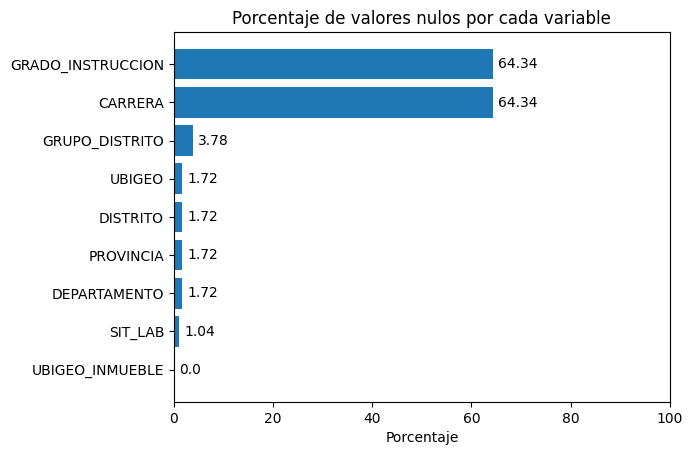

In [20]:
sbp.plot_null_percentage(df_train[lista_var_nominales])

In [21]:
# Imputamos NaN por la categoría 'Missing' y convertimos los tipos de variables nominales
for i in lista_var_nominales:
  df_train[i] = df_train[i].fillna('Missing')
  df_train[i] = df_train[i].astype('category')

### 2.3. Preselección de variables

In [22]:
print("Número de variables: ",df_train.shape[1])
print("Número de registros: ",df_train.shape[0])

Número de variables:  685
Número de registros:  509198


In [23]:
# Reemplazar los valores especiales a missing
df_train = sbp.convertir_valores_especiales_a_missing(df_train)

---

##### 2.2.1. Variables iniciales

In [24]:
# Quitando variables no predictivas
variables_a_eliminar=['EXCLUSIONES_V2','SEGMENTO_EE','EXCLUSIONES','FECNAC','FLG_NEW']
df_train.drop(variables_a_eliminar, inplace=True, axis=1)
print("Número de variables: ",df_train.shape[1])
print("\nVariables eliminadas: ", len(variables_a_eliminar),"==>" , variables_a_eliminar)

Número de variables:  680

Variables eliminadas:  5 ==> ['EXCLUSIONES_V2', 'SEGMENTO_EE', 'EXCLUSIONES', 'FECNAC', 'FLG_NEW']


In [25]:
# Quitando variables por juicio de experto (ultimo mes, input de otras,etc)
variables_a_eliminar=['CONSUMO','CONSUMO_NREV','CONSUMO_REV','CONSUMO_TOP4','F1_MES','F1_PP','F1_TC','F2_MES','F2_PP','F2_TC','F3_MES','F3_PP',
            'F3_TC','P1','P2','P3','P4','P5','P6','P7','P8','P1_60M','P2_60M','P3_60M','P4_60M','P5_60M','P6_60M','P7_60M','P8_60M','GTLWBAL1',
            'GCONSUMERCCUTILIZATION1','GAVGCONSUMERCCLIMIT1','GCCUTILIZATION1','EDAD', 'GHIGHESTBAL', 'NUM_REP_48M']

df_train.drop(variables_a_eliminar, inplace=True, axis=1)
print("Número de variables: ",df_train.shape[1])
print("\nVariables eliminadas: ", len(variables_a_eliminar),"==>" , variables_a_eliminar)

Número de variables:  644

Variables eliminadas:  36 ==> ['CONSUMO', 'CONSUMO_NREV', 'CONSUMO_REV', 'CONSUMO_TOP4', 'F1_MES', 'F1_PP', 'F1_TC', 'F2_MES', 'F2_PP', 'F2_TC', 'F3_MES', 'F3_PP', 'F3_TC', 'P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'P1_60M', 'P2_60M', 'P3_60M', 'P4_60M', 'P5_60M', 'P6_60M', 'P7_60M', 'P8_60M', 'GTLWBAL1', 'GCONSUMERCCUTILIZATION1', 'GAVGCONSUMERCCLIMIT1', 'GCCUTILIZATION1', 'EDAD', 'GHIGHESTBAL', 'NUM_REP_48M']


##### 2.2.1. Variables con alto porcentaje de missing

In [26]:
missing_df_train = pd.DataFrame(df_train.isnull().sum())
missing_df_train = missing_df_train.rename(index=str, columns={0: 'cant_missing'})
missing_df_train['porc_missing'] = missing_df_train['cant_missing']*100/len(df_train)
missing_df_train = missing_df_train.sort_values(by='porc_missing', ascending=False)
missing_df_train.query("porc_missing>=90")

,cant_missing,porc_missing
GMICROPEQUTILIZATION1TO24,509119,99.984485
DIST_MESES_MORA_30D_6M,504231,99.024544
DIST_MESES_MORA_30D_12M,499967,98.187149
DIST_MESES_MORA_8D_6M,496736,97.552622
DIST_MESES_MORA_30D_24M,494194,97.053406
DIST_MESES_MORA_8D_12M,488447,95.924768
DIST_MESES_MORA_8D_24M,475982,93.476801
RATIO_NUMTRANX_MAXSEM1_MAXSEM2,465627,91.443211
MAX_IMPORTEPEN_2SEM,465627,91.443211
RATIO_IMPORTE_MAXSEM1_MAXSEM2,465627,91.443211


In [27]:
# Eliminamos variables con mucho missing
umbral_missing = 95

missing_df_train.reset_index()
quitar_missing = missing_df_train[missing_df_train['porc_missing'] > umbral_missing]
df_train.drop(quitar_missing.index, inplace=True, axis=1)

print("Número de variables: ",df_train.shape[1])
print("\nVariables eliminadas: ", len(quitar_missing.index.to_list()),"==>" , quitar_missing.index.to_list())

Número de variables:  638

Variables eliminadas:  6 ==> ['GMICROPEQUTILIZATION1TO24', 'DIST_MESES_MORA_30D_6M', 'DIST_MESES_MORA_30D_12M', 'DIST_MESES_MORA_8D_6M', 'DIST_MESES_MORA_30D_24M', 'DIST_MESES_MORA_8D_12M']


##### 2.2.2. Variables contantes

In [28]:
# Quitando variables casi constantes (+99% de valores unicos sin incluir los NaN)
lista_var_exclusion = []
lista_var_constantes = sbp.obtener_var_constantes(df_train,var_excl=lista_var_exclusion, umbral_const=0.99)
df_train[lista_var_constantes]

,RATIO_NUMTRANX_3M_MAX6M,RATIO_NUMTRANX_3M_MED6M,RATIO_IMPORTE_3M_MAX6M,RATIO_IMPORTE_3M_MED6M
0,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN
10,NaN,NaN,NaN,NaN
...,...,...,...,...
811956,NaN,NaN,NaN,NaN
811957,NaN,NaN,NaN,NaN
811958,NaN,NaN,NaN,NaN
811959,NaN,NaN,NaN,NaN


In [29]:
df_train.drop(lista_var_constantes, inplace=True, axis=1)

print("Número de variables: ",df_train.shape[1])
print("\nVariables eliminadas: ", len(lista_var_constantes),"==>" , lista_var_constantes)

Número de variables:  634

Variables eliminadas:  4 ==> ['RATIO_NUMTRANX_3M_MAX6M', 'RATIO_NUMTRANX_3M_MED6M', 'RATIO_IMPORTE_3M_MAX6M', 'RATIO_IMPORTE_3M_MED6M']


##### 2.2.3. Multicolinealidad Categórica

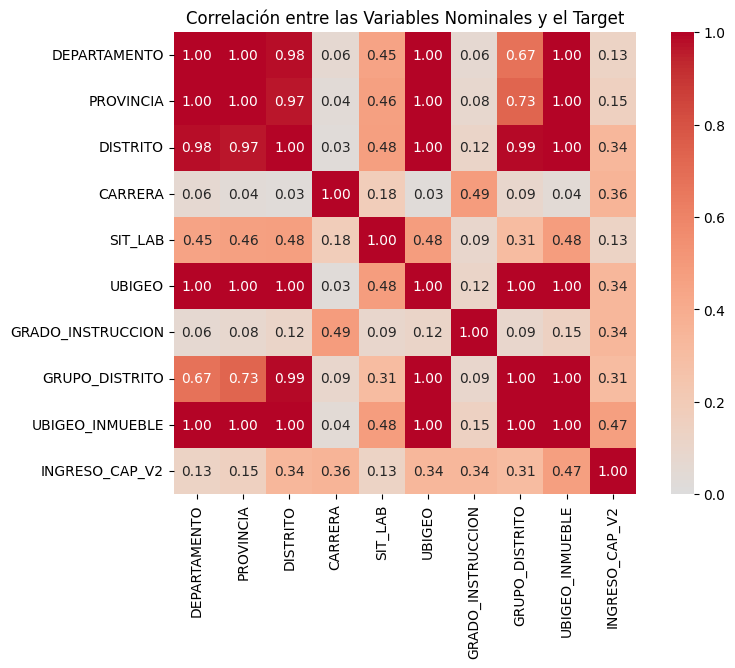

In [30]:
from dython.nominal import associations

target = ['INGRESO_CAP_V2']
df_train_mc_cat = df_train[lista_var_nominales+target]#._to_pandas()

assoc = associations(df_train_mc_cat, 
                    nominal_columns=lista_var_nominales,
                    numerical_columns=target,
                    plot=True,num_num_assoc='spearman',nom_num_assoc='correlation_ratio',nom_nom_assoc='cramer'
                    ,cmap='coolwarm',title='Correlación entre las Variables Nominales y el Target',figsize=(9,6))

In [31]:
correlations = assoc['corr']
correlations

,DEPARTAMENTO,PROVINCIA,DISTRITO,CARRERA,SIT_LAB,UBIGEO,GRADO_INSTRUCCION,GRUPO_DISTRITO,UBIGEO_INMUEBLE,INGRESO_CAP_V2
DEPARTAMENTO,1.000000,0.999832,0.983083,0.064416,0.448249,0.998260,0.063403,0.673023,0.997682,0.125857
PROVINCIA,0.999832,1.000000,0.968098,0.036694,0.464828,0.998428,0.080879,0.732044,0.997849,0.150428
DISTRITO,0.983083,0.968098,1.000000,0.028702,0.475954,0.999857,0.115231,0.987660,0.999278,0.336244
CARRERA,0.064416,0.036694,0.028702,1.000000,0.183999,0.026574,0.486740,0.091199,0.039064,0.357692
SIT_LAB,0.448249,0.464828,0.475954,0.183999,1.000000,0.477102,0.093122,0.307498,0.478404,0.125022
UBIGEO,0.998260,0.998428,0.999857,0.026574,0.477102,1.000000,0.116015,0.998248,0.999420,0.341541
GRADO_INSTRUCCION,0.063403,0.080879,0.115231,0.486740,0.093122,0.116015,1.000000,0.086568,0.147304,0.339344
GRUPO_DISTRITO,0.673023,0.732044,0.987660,0.091199,0.307498,0.998248,0.086568,1.000000,0.997669,0.310555
UBIGEO_INMUEBLE,0.997682,0.997849,0.999278,0.039064,0.478404,0.999420,0.147304,0.997669,1.000000,0.470860
INGRESO_CAP_V2,0.125857,0.150428,0.336244,0.357692,0.125022,0.341541,0.339344,0.310555,0.470860,1.000000


In [32]:
quitar_var_nom_corr = ['DEPARTAMENTO','PROVINCIA','DISTRITO','GRUPO_DISTRITO','UBIGEO']

In [33]:
df_train.drop(quitar_var_nom_corr, inplace=True, axis=1)

print("Número de variables: ",df_train.shape[1])
print("\nVariables eliminadas: ", len(quitar_var_nom_corr),"==>" , quitar_var_nom_corr)

Número de variables:  629

Variables eliminadas:  5 ==> ['DEPARTAMENTO', 'PROVINCIA', 'DISTRITO', 'GRUPO_DISTRITO', 'UBIGEO']


In [34]:
lista_var_nominales.remove('DEPARTAMENTO')
lista_var_nominales.remove('DISTRITO')
lista_var_nominales.remove('PROVINCIA')
lista_var_nominales.remove('GRUPO_DISTRITO')
lista_var_nominales.remove('UBIGEO')

##### 2.2.4. Multicolinealidad Numérica

In [35]:
df_mc = df_train.drop(columns=['ID_REGISTRO']+lista_var_nominales)
target_mc = 'INGRESO_CAP_V2'
lst_var = df_mc.columns.to_list()
lst_var.remove('INGRESO_CAP_V2')
df_mc.shape

(509198, 624)

In [36]:
with sbp.MedirTiempoEjecucion():

    df_corr = sbp.matriz_corr_target(df_mc, target_mc, lst_var)

    columnas = df_corr.columns.to_list()
    columnas.remove(target_mc)
    umbral = 0.85

    variables_eliminar = []
    for col in columnas:
        if col not in variables_eliminar:
            fila = df_corr.loc[col,:]
            for col_2 in fila.index.to_list():
                if (col_2 not in variables_eliminar)&(col_2!=col):
                    if fila[col_2] > umbral:
                        if df_corr.loc[col,target_mc] > df_corr.loc[col_2,target_mc]:
                            variables_eliminar.append(col_2)
                        else:
                            variables_eliminar.append(col)

Tiempo transcurrido: 7 horas, 0 minutos y 15.500 segundos


In [ ]:
#   Tiempo transcurrido: 4 horas, 32 minutos y 55.169 segundos

In [37]:
variables_eliminar

['MED_PAY_12M',
 'MED_PAY_6M',
 'AVG_PAY_24M',
 'AVG_PAY_12M',
 'MED_RED_CONSUMO_TOTAL_6M',
 'AVG_RED_SALDO_TOTAL_6M',
 'MED_RED_CONSUMO_TOTAL_24M',
 'MED_RED_CONSUMO_TOTAL_12M',
 'MED_RED_SALDO_TOTAL_6M',
 'MED_RED_CONSUMO_NREV_6M',
 'MED_RED_CONSUMO_TOTAL_18M',
 'MED_RED_SALDO_TOTAL_12M',
 'MED_RED_SALDO_TOTAL_24M',
 'MED_RED_CONSUMO_6M',
 'MED_RED_SALDO_TOTAL_18M',
 'MED_RED_CONSUMO_24M',
 'MED_RED_CONSUMO_12M',
 'MED_RED_CONSUMO_18M',
 'MED_RED_CONSUMO_NREV_12M',
 'MED_RED_CONSUMO_NREV_18M',
 'AVG_MAX_LINCRE_TOP4_12M',
 'AVG_MAX_LINCRE_TOP4_12M',
 'AVG_MAX_LINCRE_TOP4_12M',
 'MED_MAX_LINCRE_TOP4_12M',
 'MED_MAX_LINCRE_TOP4_24M',
 'AVG_MAX_LINCRE_24M',
 'AVG_MAX_LINCRE_12M',
 'MAX_MAX_LINCRE_24M',
 'MAX_MAX_LINCRE_12M',
 'MED_MAX_LINCRE_24M',
 'MED_MAX_LINCRE_12M',
 'GAVGCCLIMIT1TO6',
 'AVG_LINCRE_24M',
 'MAX_LINCRE_24M',
 'MAX_LINCRE_12M',
 'AVG_LINCRE_12M',
 'MAX_LINCRE_TOP4_24M',
 'MAX_LINCRE_TOP4_12M',
 'AVG_LINCRE_TOP4_24M',
 'AVG_LINCRE_TOP4_12M',
 'AVG_MAX_LINCRE_TOP4_24M',
 

In [38]:
variables_eliminar = [ 'ANTIGUEDAD_MES_120M', 'ANTIGUEDAD_TC_120M', 'ANTIGUEDAD_TC_144M', 'ANTIGUEDAD_TC_60M', 'ANTIGUEDAD_TCPP_120M', 'ANTIGUEDAD_TCPPMES_144M', 'ANTIGUEDAD_TCPPMES_60M',
'AVG_CANT_ENV_PLIN_12M', 'AVG_CANT_ENV_PLIN_6M', 'AVG_CANT_MOV_PLIN_12M', 'AVG_CANT_MOV_PLIN_3M', 'AVG_CANT_MOV_PLIN_6M', 'AVG_CANT_REC_PLIN_6M', 'AVG_CONSUMO_12M', 'AVG_CONSUMO_24M',
'AVG_CONSUMO_NREV_12M', 'AVG_CONSUMO_NREV_24M', 'AVG_CONSUMO_REV_24M', 'AVG_CONSUMO_TOP4_12M', 'AVG_CONSUMO_TOP4_24M', 'AVG_CONSUMO_TOTAL_24M', 'AVG_CONSUMO_TOTAL_48M', 
'AVG_ENT_SALDO_TOTAL_12M', 'AVG_ENT_SALDO_TOTAL_3M', 'AVG_ENT_SALDO_TOTAL_6M', 'AVG_ENT_SALDO_TOTAL_TOP4_12M', 'AVG_ENT_SALDO_TOTAL_TOP4_6M', 'AVG_LINCRE_12M', 'AVG_LINCRE_24M', 
'AVG_LINCRE_MID_12M', 'AVG_LINCRE_RET_12M', 'AVG_LINCRE_RET_24M', 'AVG_LINCRE_TOP4_12M', 'AVG_LINCRE_TOP4_24M', 'AVG_MAX_LINCRE_12M', 'AVG_MAX_LINCRE_24M', 'AVG_MAX_LINCRE_TOP4_12M', 
'AVG_MAX_LINCRE_TOP4_24M', 'AVG_MNTO_ENV_PLIN_12M', 'AVG_MNTO_ENV_PLIN_3M', 'AVG_MNTO_ENV_PLIN_6M', 'AVG_MNTO_MOV_PLIN_12M', 'AVG_MNTO_MOV_PLIN_3M', 'AVG_MNTO_MOV_PLIN_6M', 
'AVG_MNTO_REC_PLIN_12M', 'AVG_MNTO_REC_PLIN_3M', 'AVG_MNTO_REC_PLIN_6M', 'AVG_NUM_LINEAS_1000_24M', 'AVG_NUM_LINEAS_10000_24M', 'AVG_NUM_LINEAS_100000_12M', 'AVG_NUM_LINEAS_140000_12M', 
'AVG_NUM_LINEAS_200_12M', 'AVG_NUM_LINEAS_3500_12M', 'AVG_NUM_LINEAS_35000_12M', 'AVG_NUM_LINEAS_45000_12M', 'AVG_NUM_LINEAS_45000_24M', 'AVG_NUM_LINEAS_80000_12M', 
'AVG_NUM_LINEAS_PEERS_12M', 'AVG_PASIVOS_HM_12M', 'AVG_PASIVOS_HM_6M', 'AVG_PASIVOS_HMOD_12M', 'AVG_PASIVOS_HMOD_6M', 'AVG_PAY_12M', 'AVG_PAY_24M', 'AVG_PERC_CC_USE_12M', 
'AVG_PERC_CC_USE_24M', 'AVG_PERC_CC_USE_3M', 'AVG_PERC_CC_USE_6M', 'AVG_RATIO_LINEA_12M', 'AVG_RATIO_LINEA_24M', 'AVG_RATIO_SALDO_UTIL_12M', 'AVG_RATIO_SALDO_UTIL_24M', 
'AVG_RATIO_SALDO_UTIL_TOP4_12M', 'AVG_RATIO_SALDO_UTIL_TOP4_24M', 'AVG_RATIO_SALDO_UTIL_TOP4_USO12M_12M', 'AVG_RATIO_SALDO_UTIL_USO12M_12M', 'AVG_RATIO_SALDO_UTIL_USO24M_24M', 
'AVG_RED_COMPRAS_TC_12M', 'AVG_RED_COMPRAS_TC_18M', 'AVG_RED_COMPRAS_TC_24M', 'AVG_RED_COMPRAS_TC_3M', 'AVG_RED_COMPRAS_TC_6M', 'AVG_RED_CONSUMO_12M', 'AVG_RED_CONSUMO_18M', 
'AVG_RED_CONSUMO_24M', 'AVG_RED_CONSUMO_3M', 'AVG_RED_CONSUMO_6M', 'AVG_RED_CONSUMO_NREV_18M', 'AVG_RED_CONSUMO_NREV_24M', 'AVG_RED_CONSUMO_NREV_6M', 'AVG_RED_CONSUMO_TOTAL_12M', 
'AVG_RED_CONSUMO_TOTAL_18M', 'AVG_RED_CONSUMO_TOTAL_6M', 'AVG_RED_SALDO_TOTAL_12M', 'AVG_RED_SALDO_TOTAL_18M', 'AVG_RED_SALDO_TOTAL_24M', 'AVG_RED_SALDO_TOTAL_3M', 
'AVG_RED_SALDO_TOTAL_6M', 'AVG_SALDO_TOTAL_12M', 'AVG_SALDO_TOTAL_24M', 'AVG_SALDO_TOTAL_MID_12M', 'AVG_SALDO_TOTAL_RET_12M', 'AVG_SALDO_TOTAL_TOP4_24M', 'CLAS_MAX_12M', 'CLAS_MAX_24M', 
'CLAS_MAX_3M', 'CLAS_MAX_48M', 'CLAS_MAX_60M', 'CLAS_MAX_6M', 'COEFVAR_CONSUMO_12M', 'COEFVAR_CONSUMO_24M', 'COEFVAR_CONSUMO_48M', 'COEFVAR_CONSUMO_6M', 'COEFVAR_CONSUMO_REV_6M', 
'COEFVAR_CONSUMO_TOP4_12M', 'COEFVAR_CONSUMO_TOP4_24M', 'COEFVAR_CONSUMO_TOP4_48M', 'COEFVAR_CONSUMO_TOP4_6M', 'COEFVAR_LINCRE_12M', 'COEFVAR_LINCRE_24M', 'COEFVAR_SALDO_TOTAL_12M', 
'COEFVAR_SALDO_TOTAL_6M', 'COEFVAR_SALDO_UTIL_12M', 'COEFVAR_SALDO_UTIL_24M', 'COEFVAR_SALDO_UTIL_48M', 'COEFVAR_SALDO_UTIL_6M', 'COMP_FIN', 'DIASMORA_MAX_U12M', 'DIASMORA_MAX_U3M', 
'DIST_CPP_144M', 'DIST_CPP_O_PEOR_144M', 'DIST_CPP_O_PEOR_60M', 'DIST_DEFICIENTE_60M', 'DIST_DEFICIENTE_O_PEOR_120M', 'DIST_DEFICIENTE_O_PEOR_48M', 'DIST_DEFICIENTE_O_PEOR_60M', 
'DIST_DUDOSO_120M', 'DIST_DUDOSO_144M', 'DIST_DUDOSO_O_PEOR_144M', 'DIST_DUDOSO_O_PEOR_48M', 'DIST_MONTH_PAY_12M', 'DIST_MONTH_PAY_6M', 'DIST_NORMAL_120M', 'DIST_PERDIDA_120M', 
'DIST_PERDIDA_144M', 'DIST_PERDIDA_48M', 'DIST_PERDIDA_60M', 'FLAG_DEF_DUDO_PERDIDA_144M', 'FLAG_DEFICIENTE_144M', 'FLAG_HIPOTECARIO_24M', 'FLAG_HIPOTECARIO_48M', 'GAVGCCLIMIT1TO6', 
'GBAL1PCTAVGBAL1TO12', 'GBAL1PCTAVGBAL1TO24', 'GBAL1PCTAVGBAL1TO36', 'GCCUTILIZATION1TO12', 'GCCUTILIZATION1TO18', 'GCCUTILIZATION1TO24', 'GCCUTILIZATION1TO6', 'GCLEANDELQFLAG1TO12', 
'GCONSUMERCCUTILIZATION1TO12', 'GCONSUMERCCUTILIZATION1TO18', 'GCONSUMERCCUTILIZATION1TO24', 'GCONSUMERCCUTILIZATION1TO6', 'GMICROPEQTL', 'GNUMCREDITTL', 'GPCTTLNEVERDELQ', 'GREVTL', 
'GREVTLWBAL1TO12', 'GSCOTIA_WORST48M_ALT2', 'GTLWBAL1TO12', 'GWORSTILTLRATING', 'GWORSTTLRATING1TO24', 'GWORSTTLRATING1TO36', 'GWORSTTLRATING1TO48', 'MAX_ATRASO_24M', 'MAX_ATRASO_48M', 
'MAX_ATRASO_TOTAL_12M', 'MAX_ATRASO_TOTAL_24M', 'MAX_ATRASO_TOTAL_48M', 'MAX_ATRASO_TOTAL_60M', 'MAX_CANT_ENV_PLIN_12M', 'MAX_CANT_ENV_PLIN_3M', 'MAX_CANT_ENV_PLIN_6M', 
'MAX_CANT_MOV_PLIN_12M', 'MAX_CANT_MOV_PLIN_3M', 'MAX_CANT_MOV_PLIN_6M', 'MAX_CANT_REC_PLIN_12M', 'MAX_CANT_REC_PLIN_3M', 'MAX_CANT_REC_PLIN_6M', 'MAX_COMPRAS_TC_24M', 'MAX_CONSUMO_12M', 
'MAX_CONSUMO_48M', 'MAX_CONSUMO_60M', 'MAX_CONSUMO_NREV_12M', 'MAX_CONSUMO_REV_12M', 'MAX_CONSUMO_REV_24M', 'MAX_CONSUMO_TOP4_12M', 'MAX_CONSUMO_TOP4_24M', 'MAX_CONSUMO_TOP4_48M', 
'MAX_CONSUMO_TOTAL_48M', 'MAX_CONSUMO_TOTAL_60M', 'MAX_ENT_SALDO_TOTAL_12M', 'MAX_ENT_SALDO_TOTAL_6M', 'MAX_ENT_SALDO_TOTAL_TOP4_12M', 'MAX_ENT_SALDO_TOTAL_TOP4_3M', 
'MAX_ENT_SALDO_TOTAL_TOP4_6M', 'MAX_ENT_SALDO_UTIL_12M', 'MAX_ENT_SALDO_UTIL_3M', 'MAX_ENT_SALDO_UTIL_6M', 'MAX_GARHIP_2010', 'MAX_GARJOY_120M', 'MAX_GARVEH_120M', 'MAX_GASTO_TC_6M', 
'MAX_HIPOTECARIO_120M', 'MAX_HIPOTECARIO_24M', 'MAX_HIPOTECARIO_48M', 'MAX_HIPOTECARIO_60M', 'MAX_HIPOTECARIO_SMV_120M', 'MAX_HIPOTECARIO_SMV_2010', 'MAX_IMPORTEPEN_2SEM', 
'MAX_IMPORTEPEN_3M', 'MAX_IMPORTEPEN_6M', 'MAX_LINCRE_12M', 'MAX_LINCRE_24M', 'MAX_LINCRE_RET_12M', 'MAX_LINCRE_TOP4_12M', 'MAX_LINCRE_TOP4_24M', 'MAX_MAX_LINCRE_12M', 
'MAX_MAX_LINCRE_24M', 'MAX_MAX_LINCRE_TOP4_12M', 'MAX_MAXPLAZO_3M', 'MAX_MAXPLAZO_6M', 'MAX_MNTO_ENV_PLIN_3M', 'MAX_MNTO_ENV_PLIN_6M', 'MAX_MNTO_MOV_PLIN_12M', 'MAX_MNTO_MOV_PLIN_3M', 
'MAX_MNTO_MOV_PLIN_6M', 'MAX_MNTO_REC_PLIN_12M', 'MAX_MNTO_REC_PLIN_3M', 'MAX_MORA_12M', 'MAX_NUMPLAZO_12M', 'MAX_NUMPLAZO_2SEM', 'MAX_NUMPLAZO_3M', 'MAX_NUMPLAZO_6M', 
'MAX_NUMTRANX_2SEM', 'MAX_NUMTRANX_3M', 'MAX_NUMTRANX_6M', 'MAX_PAY_12M', 'MAX_PAY_6M', 'MAX_PERC_CC_USE_12M', 'MAX_PERC_CC_USE_24M', 'MAX_PERC_CC_USE_3M', 'MAX_RATIO_LINEA_12M', 
'MAX_RATIO_SALDO_UTIL_12M', 'MAX_RATIO_SALDO_UTIL_TOP4_12M', 'MAX_RATIO_SALDO_UTIL_TOP4_24M', 'MAX_RATIO_SALDO_UTIL_TOP4_USO12M_12M', 'MAX_RATIO_SALDO_UTIL_TOP4_USO24M_24M', 
'MAX_RATIO_SALDO_UTIL_USO12M_12M', 'MAX_RATIO_SALDO_UTIL_USO24M_24M', 'MAX_RED_COMPRAS_TC_12M', 'MAX_RED_COMPRAS_TC_18M', 'MAX_RED_COMPRAS_TC_24M', 'MAX_RED_COMPRAS_TC_3M', 
'MAX_SALDO_TOTAL_12M', 'MAX_SALDO_TOTAL_24M', 'MAX_SALDO_TOTAL_48M', 'MAX_SALDO_TOTAL_60M', 'MAX_VEHICULAR_48M', 'MED_CANT_ENV_PLIN_12M', 'MED_CANT_ENV_PLIN_3M', 'MED_CANT_ENV_PLIN_6M', 
'MED_CANT_MOV_PLIN_12M', 'MED_CANT_MOV_PLIN_3M', 'MED_CANT_MOV_PLIN_6M', 'MED_CANT_REC_PLIN_12M', 'MED_CANT_REC_PLIN_3M', 'MED_CANT_REC_PLIN_6M', 'MED_IMPORTEPEN_12M', 
'MED_IMPORTEPEN_2SEM', 'MED_IMPORTEPEN_3M', 'MED_IMPORTEPEN_6M', 'MED_MAX_LINCRE_12M', 'MED_MAX_LINCRE_24M', 'MED_MAX_LINCRE_TOP4_12M', 'MED_MAX_LINCRE_TOP4_24M', 'MED_MNTO_ENV_PLIN_12M', 
'MED_MNTO_ENV_PLIN_3M', 'MED_MNTO_ENV_PLIN_6M', 'MED_MNTO_MOV_PLIN_12M', 'MED_MNTO_MOV_PLIN_3M', 'MED_MNTO_REC_PLIN_3M', 'MED_MNTO_REC_PLIN_6M', 'MED_NUMTRANX_12M', 'MED_NUMTRANX_2SEM', 
'MED_NUMTRANX_3M', 'MED_NUMTRANX_6M', 'MED_PASIVOS_HM_12M', 'MED_PASIVOS_HM_6M', 'MED_PASIVOS_HM_MIN3_6M', 'MED_PASIVOS_HM_MIN6_12M', 'MED_PASIVOS_HMOD_12M', 'MED_PASIVOS_HMOD_6M', 
'MED_PASIVOS_HMOD_MIN3_6M', 'MED_PASIVOS_HMOD_MIN6_12M', 'MED_PASIVOS_IC_12M', 'MED_PASIVOS_IC_6M', 'MED_PASIVOS_IC_MIN6_12M', 'MED_PAY_12M', 'MED_PAY_6M', 'MED_PERC_CC_USE_12M', 
'MED_PERC_CC_USE_24M', 'MED_PERC_CC_USE_3M', 'MED_PERC_CC_USE_6M', 'MED_RATIO_SALDO_UTIL_12M', 'MED_RATIO_SALDO_UTIL_24M', 'MED_RATIO_SALDO_UTIL_TOP4_12M', 
'MED_RATIO_SALDO_UTIL_TOP4_24M', 'MED_RATIO_SALDO_UTIL_TOP4_USO12M_12M', 'MED_RATIO_SALDO_UTIL_TOP4_USO24M_24M', 'MED_RATIO_SALDO_UTIL_USO12M_12M', 'MED_RATIO_SALDO_UTIL_USO24M_24M', 
'MED_RED_COMPRAS_TC_18M', 'MED_RED_COMPRAS_TC_24M', 'MED_RED_COMPRAS_TC_6M', 'MED_RED_CONSUMO_12M', 'MED_RED_CONSUMO_18M', 'MED_RED_CONSUMO_24M', 'MED_RED_CONSUMO_3M', 
'MED_RED_CONSUMO_6M', 'MED_RED_CONSUMO_NREV_12M', 'MED_RED_CONSUMO_NREV_18M', 'MED_RED_CONSUMO_NREV_3M', 'MED_RED_CONSUMO_NREV_6M', 'MED_RED_CONSUMO_TOTAL_12M', 
'MED_RED_CONSUMO_TOTAL_18M', 'MED_RED_CONSUMO_TOTAL_24M', 'MED_RED_CONSUMO_TOTAL_3M', 'MED_RED_CONSUMO_TOTAL_6M', 'MED_RED_SALDO_TOTAL_12M', 'MED_RED_SALDO_TOTAL_18M', 
'MED_RED_SALDO_TOTAL_24M', 'MED_RED_SALDO_TOTAL_3M', 'MED_RED_SALDO_TOTAL_6M', 'MESES_DIASMORA_NUM_U12M', 'MESES_DIASMORA_NUM_U3M', 'MESES_DIASMORA_NUM_U6M', 'NUM_CPP_144M', 
'NUM_CPP_60M', 'NUM_CPP_O_PEOR_120M', 'NUM_CPP_O_PEOR_144M', 'NUM_CPP_O_PEOR_48M', 'NUM_CPP_O_PEOR_60M', 'NUM_DEFICIENTE_144M', 'NUM_DEFICIENTE_48M', 'NUM_DEFICIENTE_O_PEOR_120M', 
'NUM_DEFICIENTE_O_PEOR_144M', 'NUM_DEFICIENTE_O_PEOR_48M', 'NUM_DEFICIENTE_O_PEOR_60M', 'NUM_DUDOSO_120M', 'NUM_DUDOSO_144M', 'NUM_DUDOSO_60M', 'NUM_DUDOSO_O_PEOR_120M', 
'NUM_DUDOSO_O_PEOR_144M', 'NUM_DUDOSO_O_PEOR_48M', 'NUM_DUDOSO_O_PEOR_60M', 'NUM_MESES_MORA_30D_12M', 'NUM_MESES_MORA_8D_12M', 'NUM_MESES_MORA_8D_6M', 'NUM_NORMAL_120M', 
'NUM_NORMAL_144M', 'NUM_NORMAL_24M', 'NUM_NORMAL_48M', 'NUM_PASIVOS_HM_6M', 'NUM_PASIVOS_HMOD_12M', 'NUM_PASIVOS_HMOD_6M', 'NUM_PASIVOS_IC_12M', 'NUM_PASIVOS_IC_6M', 'NUM_PAY_12M', 
'NUM_PERDIDA_120M', 'NUM_PERDIDA_12M', 'NUM_PERDIDA_144M', 'NUM_PERDIDA_48M', 'NUM_PERDIDA_60M', 'PATRON_CLASIFICACION', 'PRECIO_ALQUILER_M2', 'PRECIO_VENTA_M2', 'PRECIO_VENTA_TOTAL', 
'PROP_POB_INICIAL_U', 'PROP_POB_POB_EDU_BASICA_U', 'PROP_POB_POB_EDU_SUPERIOR_U', 'PROP_POB_PRIMARIA_U', 'RATIO_IMPORTE_1M_MAX12M', 'RATIO_IMPORTE_1M_MAX3M', 'RATIO_IMPORTE_1M_MAX6M', 
'RATIO_IMPORTE_1M_MED3M', 'RATIO_IMPORTE_1M_MED6M', 'RATIO_IMPORTE_3M_MAX12M', 'RATIO_IMPORTE_3M_MED12M', 'RATIO_NUMTRANX_1M_MAX3M', 'RATIO_NUMTRANX_1M_MAX6M', 'RATIO_NUMTRANX_1M_MED6M', 
'RATIO_NUMTRANX_MAXSEM1_MAXSEM2', 'RATIO_PAGO_24M', 'RATIO_PAGO_6M', 'SUM_CANT_ENV_PLIN_3M', 'SUM_CANT_ENV_PLIN_6M', 'SUM_CANT_MOV_PLIN_12M', 'SUM_CANT_MOV_PLIN_3M', 
'SUM_CANT_REC_PLIN_12M', 'SUM_CANT_REC_PLIN_3M', 'SUM_CANT_REC_PLIN_6M', 'SUM_MNTO_ENV_PLIN_12M', 'SUM_MNTO_ENV_PLIN_6M', 'SUM_MNTO_MOV_PLIN_3M', 'SUM_MNTO_MOV_PLIN_6M', 
'SUM_MNTO_REC_PLIN_12M', 'SUM_MNTO_REC_PLIN_3M', 'SUM_MNTO_REC_PLIN_6M', 'SUM_NUMTRANX_12M', 'SUM_NUMTRANX_2SEM', 'SUM_NUMTRANX_3M', 'SUM_NUMTRANX_6M', 'VAR_CONSUMO_12M']

In [39]:
df_train.drop(variables_eliminar, inplace=True, axis=1)

print("Número de variables: ",df_train.shape[1])
print("\nVariables eliminadas: ", len(variables_eliminar),"==>" , variables_eliminar)

Número de variables:  204

Variables eliminadas:  425 ==> ['ANTIGUEDAD_MES_120M', 'ANTIGUEDAD_TC_120M', 'ANTIGUEDAD_TC_144M', 'ANTIGUEDAD_TC_60M', 'ANTIGUEDAD_TCPP_120M', 'ANTIGUEDAD_TCPPMES_144M', 'ANTIGUEDAD_TCPPMES_60M', 'AVG_CANT_ENV_PLIN_12M', 'AVG_CANT_ENV_PLIN_6M', 'AVG_CANT_MOV_PLIN_12M', 'AVG_CANT_MOV_PLIN_3M', 'AVG_CANT_MOV_PLIN_6M', 'AVG_CANT_REC_PLIN_6M', 'AVG_CONSUMO_12M', 'AVG_CONSUMO_24M', 'AVG_CONSUMO_NREV_12M', 'AVG_CONSUMO_NREV_24M', 'AVG_CONSUMO_REV_24M', 'AVG_CONSUMO_TOP4_12M', 'AVG_CONSUMO_TOP4_24M', 'AVG_CONSUMO_TOTAL_24M', 'AVG_CONSUMO_TOTAL_48M', 'AVG_ENT_SALDO_TOTAL_12M', 'AVG_ENT_SALDO_TOTAL_3M', 'AVG_ENT_SALDO_TOTAL_6M', 'AVG_ENT_SALDO_TOTAL_TOP4_12M', 'AVG_ENT_SALDO_TOTAL_TOP4_6M', 'AVG_LINCRE_12M', 'AVG_LINCRE_24M', 'AVG_LINCRE_MID_12M', 'AVG_LINCRE_RET_12M', 'AVG_LINCRE_RET_24M', 'AVG_LINCRE_TOP4_12M', 'AVG_LINCRE_TOP4_24M', 'AVG_MAX_LINCRE_12M', 'AVG_MAX_LINCRE_24M', 'AVG_MAX_LINCRE_TOP4_12M', 'AVG_MAX_LINCRE_TOP4_24M', 'AVG_MNTO_ENV_PLIN_12M', 'AVG_MNTO_

---

---

## 3.Analisis Exploratorio

### 3.1. Auto EDA

In [40]:
lista_var_excl = ['ID_REGISTRO']
lista_var_cat = lista_var_nominales
ruta_eda = "C://Users//s2660778//The Bank of Nova Scotia//Gonzales Cornejo, Kevin Fausto - 023. Estimador_Ingresos_Cliente//Sprint 4//Single_Model_VF2//01.EDA_Preproc"
target = "INGRESO_CAP_V2"
df = df_train

In [41]:
sbp.eda_vf2(df=df,target=target,var_excluidas=lista_var_excl,var_categoricas=lista_var_cat,ruta_eda=ruta_eda)

.Correlacion spearman
..Eda
...Bivariado:
....1. MED_PAY_24M
....2. MED_RCC_S_TOT_U12M_6CONS
....3. MAX_MAX_LINCRE_TOP4_24M
....4. AVG_PAY_6M
....5. MAX_HIPOTECARIO_2010
....6. GHIGHESTBAL_NORM48
....7. MAX_IMPORTEPEN_12M
....8. AVG_RED_CONSUMO_TOTAL_3M
....9. MAX_GARHIP_120M
....10. MAX_PAY_24M
....11. AVG_RED_CONSUMO_NREV_3M
....12. GAVGCCLIMIT1TO48
....13. AVG_RED_CONSUMO_TOTAL_24M
....14. MAX_GASTO_TC_12M
....15. AVG_CONSUMO_TOTAL_60M
....16. MED_RED_CONSUMO_NREV_24M
....17. AVG_RED_CONSUMO_NREV_12M
....18. AVG_NUM_LINEAS_10000_12M
....19. MAX_CONSUMO_TOP4_60M
....20. CLASIFF_POWER_MALBIE2_144M
....21. AVG_SALDO_TOTAL_TOP4_12M
....22. MAX_RED_COMPRAS_TC_6M
....23. MAX_RATIO_LINEA_24M
....24. MAX_CONSUMO_24M
....25. AVG_NUM_LINEAS_3500_24M
....26. GRUPO_GRADO
....27. MAX_COMPRAS_TC_48M
....28. MED_RED_COMPRAS_TC_3M
....29. AVG_NUM_LINEAS_35000_24M
....30. NUM_NORMAL_60M
....31. AVG_CONSUMO_REV_12M
....32. MED_RED_COMPRAS_TC_12M
....33. MAX_NUMTRANX_12M
....34. GMOSWBAL1TO48
....35. 

---

# 4.Importancia de variables
---

### 4.1.Regresión Elastic-Net

In [42]:
df_train.head(3)

,ID_REGISTRO,MED_RCC_S_TOT_U12M_6CONS,INGRESO_CAP_V2,GILTL,GREVTLWBAL,GMICROTL,GILTLRATEDNORMAL,GILTLWBAL1TO12,GBAL1PCTAVGBAL1TO48,GBAL1PCTAVGBAL1TO9,GBAL1PCTAVGBAL1TO18,GTLWBAL1TO6,GBAL1PCTMAXBAL1TO12,GREVTLWBAL1TO6,GAVGCCLIMIT1TO48,GBAL1PCTAVGBAL1TO3,GCCUTILIZATION1TO36,GOLDESTMONTHRPTDRCC1TO48,GCLEANDELQFLAG,GTLNEVERRATED121P,GAVGMOSRATEDNORMAL,GMOSWBAL1TO48,GREVTLRATEDNORMAL,GBAL1PCTMAXBAL1TO48,GWORSTMICROPEQTLRATING,MAX_CONSUMO_NREV_24M,VAR_CONSUMO_NREV_12M,MAX_PERC_CC_USE_6M,AVG_RED_CONSUMO_TOTAL_3M,AVG_CONSUMO_TOTAL_60M,MAX_CONSUMO_TOP4_60M,VAR_CONSUMO_TOP4_12M,AVG_ENT_SALDO_TOTAL_TOP4_3M,AVG_CONSUMO_REV_12M,AVG_SALDO_TOTAL_TOP4_12M,MED_RED_CONSUMO_NREV_24M,MAX_ENT_SALDO_TOTAL_3M,VAR_CONSUMO_REV_12M,MAX_LINCRE_RET_24M,AVG_RED_CONSUMO_TOTAL_24M,MAX_ATRASO_60M,MAX_ATRASO_12M,MAX_VEHICULAR_24M,FLAG_HIPOTECARIO_60M,AVG_SALDO_TOTAL_RET_24M,MAX_COMPRAS_TC_48M,AVG_RED_CONSUMO_NREV_3M,MAX_VEHICULAR_60M,MAX_RED_COMPRAS_TC_6M,AVG_RED_CONSUMO_NREV_12M,MAX_RATIO_LINEA_24M,MED_RED_COMPRAS_TC_12M,MED_RED_COMPRAS_TC_3M,AVG_SALDO_TOTAL_MID_24M,AVG_LINCRE_MID_24M,MAX_CONSUMO_24M,AVG_NUM_LINEAS_100000_24M,AVG_NUM_LINEAS_1000_12M,MAX_GARHIP_120M,MAX_MAX_LINCRE_TOP4_24M,AVG_NUM_LINEAS_80000_24M,MAX_GARJOY_2010,AVG_NUM_LINEAS_140000_24M,MAX_RATIO_SALDO_UTIL_24M,AVG_NUM_LINEAS_200_24M,AVG_NUM_LINEAS_PEERS_24M,MAX_HIPOTECARIO_2010,AVG_NUM_LINEAS_35000_24M,AVG_NUM_LINEAS_3500_24M,AVG_NUM_LINEAS_10000_12M,MAX_GARVEH_2010,AVG_RATIO_SALDO_UTIL_TOP4_USO24M_24M,COEFVAR_LINCRE_TOP4_12M,COEFVAR_CONSUMO_NREV_6M,COEFVAR_CONSUMO_NREV_24M,COEFVAR_LINCRE_48M,COEFVAR_LINCRE_TOP4_48M,COEFVAR_CONSUMO_REV_24M,COEFVAR_SALDO_TOTAL_TOP4_6M,COEFVAR_LINCRE_TOP4_6M,COEFVAR_SALDO_TOTAL_24M,COEFVAR_SALDO_UTIL_TOP4_12M,COEFVAR_SALDO_UTIL_TOP4_24M,COEFVAR_CONSUMO_NREV_48M,COEFVAR_SALDO_TOTAL_TOP4_24M,COEFVAR_CONSUMO_REV_48M,COEFVAR_SALDO_TOTAL_TOP4_12M,COEFVAR_CONSUMO_REV_12M,COEFVAR_SALDO_UTIL_TOP4_6M,COEFVAR_SALDO_TOTAL_48M,COEFVAR_SALDO_TOTAL_TOP4_48M,COEFVAR_LINCRE_TOP4_24M,COEFVAR_CONSUMO_NREV_12M,COEFVAR_SALDO_UTIL_TOP4_48M,COEFVAR_LINCRE_6M,NUM_CPP_48M,DIST_CPP_O_PEOR_48M,DIST_CPP_O_PEOR_120M,NUM_DEFICIENTE_60M,DIST_DEFICIENTE_O_PEOR_144M,FLAG_DEF_DUDO_PERDIDA_120M,NUM_NORMAL_60M,DIST_DUDOSO_O_PEOR_60M,DIST_CPP_60M,NUM_DEFICIENTE_24M,FLAG_CPP_144M,NUM_DUDOSO_24M,DIST_NORMAL_144M,NUM_DUDOSO_12M,DIST_DUDOSO_60M,NUM_DEFICIENTE_12M,DIST_CPP_120M,NUM_PERDIDA_24M,FLAG_PERDIDA_144M,NUM_DUDOSO_48M,CLASIFF_POWER_MALBIE2_144M,NUM_CPP_24M,DIST_DUDOSO_O_PEOR_120M,DIST_DEFICIENTE_144M,NUM_CPP_12M,NUM_DEFICIENTE_120M,N_ULT_CLAS_CONT_60M,PATRON_60M,NUM_CPP_120M,NUM_NORMAL_12M,DIST_NORMAL_60M,FLAG_DUDOSO_144M,PATRON,DIST_DEFICIENTE_120M,GHIGHESTBAL_NORM48,ANTIGUEDAD_PP_60M,ANTIGUEDAD_PP_144M,ANTIGUEDAD_TCPP_144M,ANTIGUEDAD_TCPPMES_120M,ANTIGUEDAD_PP_120M,ANTIGUEDAD_TCPP_60M,ANTIGUEDAD_MES_144M,ANTIGUEDAD_MES_60M,GRUPO_DEP_GASTO,CARRERA,FLAG_INMUEBLE,IDH,NEW_DEMO,MAX_GRUPO_VEHICULO,SIT_LAB,NSE,PROP_POB_SECUNDARIA_U,GRADO_INSTRUCCION,GRUPO_GRADO,MAX_ANIO_VEHICULO,GRUPO_DEP_INGRESO,NUM_VEHICULOS,PROP_POB_PEA_OCUPADA_U,NR_INUNDACION,ZONAV_CAL,PRECIO_ALQUILER_TOTAL,UBIGEO_INMUEBLE,NR_MOV_MASAS,DIST_MONTH_PAY_24M,NUM_MESES_MORA_30D_24M,MAX_MORA_24M,MAX_MORA_6M,NUM_SMALL_PAY_24M,NUM_PAY_24M,NUM_MESES_MORA_8D_24M,DIST_MESES_MORA_8D_24M,AVG_PAY_6M,MED_PAY_24M,MAX_PAY_24M,NUM_PAY_6M,NUM_MESES_MORA_30D_6M,NUM_SMALL_PAY_12M,RATIO_PAGO_12M,NUM_SMALL_PAY_6M,MED_PASIVOS_IC_MIN3_6M,AVG_PASIVOS_IC_12M,AVG_PASIVOS_IC_6M,NUM_PASIVOS_HM_12M,MAX_GASTO_TC_12M,MAX_MAXPLAZO_2SEM,RATIO_IMPORTE_MAXSEM1_MAXSEM2,RATIO_NUMTRANX_3M_MED12M,RATIO_NUMTRANX_1M_MAX12M,MAX_IMPORTEPEN_12M,RATIO_IMPORTE_1M_MED12M,RATIO_NUMTRANX_1M_MED3M,RATIO_NUMTRANX_3M_MAX12M,RATIO_NUMTRANX_1M_MED12M,MAX_MAXPLAZO_12M,RATIO_IMPORTE_MEDSEM1_MEDSEM2,MAX_NUMTRANX_12M,RATIO_NUMTRANX_MEDSEM1_MEDSEM2,AVG_CANT_REC_PLIN_3M,MED_MNTO_REC_PLIN_12M,SUM_MNTO_MOV_PLIN_12M,MAX_MNTO_REC_PLIN_6M,MED_MNTO_MOV_PLIN_6M,SUM_MNTO_ENV_PLIN_3M,AVG_CANT_REC_PLIN_12M,MONTO_TRANSACCIONES_12M,SUM_CANT_MOV_PLIN_6M,MAX_MNTO_ENV_PLIN_12M,AVG_CANT_ENV_PLIN_3M,SU

In [43]:
lista_var_nominales

['CARRERA', 'SIT_LAB', 'GRADO_INSTRUCCION', 'UBIGEO_INMUEBLE']

In [44]:
X_train = df_train.drop(columns=["ID_REGISTRO","INGRESO_CAP_V2"])
y_train = df_train["INGRESO_CAP_V2"]

In [45]:
for col in lista_var_nominales:
    le = LabelEncoder()
    X_train[col] = le.fit_transform(X_train[col])

In [46]:
X_train = X_train.fillna(0)

In [47]:
#from sklearn.linear_model import SGDClassifier
with sbp.MedirTiempoEjecucion():

    # Crear el modelo de Elastic Net para clasificación
    #model = make_pipeline(StandardScaler(), SGDClassifier(loss='log', penalty='elasticnet', alpha=0.01, l1_ratio=0.5, random_state=666))
    elastic_net_model = make_pipeline(StandardScaler(), SGDRegressor(loss='squared_error', penalty='elasticnet', random_state=666))
    elastic_net_model.fit(X_train, y_train)

    pass

Tiempo transcurrido: 0 horas, 0 minutos y 14.977 segundos


In [48]:
# Obtener el estimador final del pipeline
sgd_regressor = elastic_net_model.named_steps['sgdregressor']

In [49]:
# Valor absoluto de los coeficientes (Contribución parcial de las variables)
coefficients = pd.DataFrame(np.abs(sgd_regressor.coef_.flatten()), index = X_train.columns, columns=['Coefficient'])
coefficients

,Coefficient
MED_RCC_S_TOT_U12M_6CONS,6.935989e+08
GILTL,2.102261e+08
GREVTLWBAL,2.357483e+08
GMICROTL,8.106817e+07
GILTLRATEDNORMAL,2.424491e+08
GILTLWBAL1TO12,6.022187e+08
GBAL1PCTAVGBAL1TO48,3.154906e+08
GBAL1PCTAVGBAL1TO9,3.519158e+08
GBAL1PCTAVGBAL1TO18,6.939900e+08
GTLWBAL1TO6,1.116932e+09


### 4.2. Random Forest

In [50]:
X_train = df_train.drop(columns=["ID_REGISTRO","INGRESO_CAP_V2"])
y_train = df_train["INGRESO_CAP_V2"]

In [51]:
for col in lista_var_nominales:
    le = LabelEncoder()
    X_train[col] = le.fit_transform(X_train[col])

In [52]:
X_train = X_train.fillna(0)

In [53]:
with sbp.MedirTiempoEjecucion():

    forest = RandomForestRegressor(random_state=666,n_jobs=-1)
    forest.fit(X_train, y_train)

    pass

Tiempo transcurrido: 0 horas, 46 minutos y 5.544 segundos


In [54]:
importancias = forest.feature_importances_
# caracteristicas_importantes = sorted(zip(importancias, features), reverse=True)

df_importancias = pd.DataFrame({
    'Característica': X_train.columns,
    'Importancia': importancias
}).sort_values('Importancia', ascending=False).reset_index(drop=True)

df_importancias

,Característica,Importancia
0,GHIGHESTBAL_NORM48,0.272762
1,MAX_GARHIP_120M,0.101417
2,MAX_MAX_LINCRE_TOP4_24M,0.090306
3,MED_PAY_24M,0.055879
4,MED_PASIVOS_IC_MIN3_6M,0.031122
5,GRUPO_GRADO,0.020880
6,MAX_CONSUMO_TOP4_60M,0.015979
7,MAX_COMPRAS_TC_48M,0.015919
8,MAX_HIPOTECARIO_2010,0.015191
9,GAVGCCLIMIT1TO48,0.010782


### 4.3. LightGBM

In [55]:
X_train = df_train.drop(columns=["ID_REGISTRO","INGRESO_CAP_V2"])
y_train = df_train["INGRESO_CAP_V2"]

In [56]:
with sbp.MedirTiempoEjecucion():
    #gbm = lgb.LGBMClassifier(random_state=666)
    #gbm.fit(X_train, y_train)
    gbm = lgb.LGBMRegressor(random_state=666)
    gbm.fit(X_train, y_train,categorical_feature=lista_var_nominales)

[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.179369 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 29205
[LightGBM] [Info] Number of data points in the train set: 509198, number of used features: 202
[LightGBM] [Info] Start training from score 3595.185571
Tiempo transcurrido: 0 horas, 0 minutos y 23.998 segundos


In [59]:
sbp.importancias_lgbm_v2(gbm,X_train)

,Var,Split_Importance,Gain_Importance,Split_Weight,Gain_Weight,Avg_Weight,H_Avg_Weight
0,MAX_GARHIP_120M,100,6.676077e+12,0.033333,0.220831,0.127082,0.097491
1,MED_PAY_24M,126,2.154208e+12,0.042000,0.071257,0.056628,0.088952
2,MED_PASIVOS_IC_MIN3_6M,171,1.173036e+12,0.057000,0.038802,0.047901,0.077713
3,UBIGEO_INMUEBLE,427,7.078398e+11,0.142333,0.023414,0.082874,0.067682
4,MAX_MAX_LINCRE_TOP4_24M,71,3.758295e+12,0.023667,0.124317,0.073992,0.066926
5,CARRERA,164,7.656185e+11,0.054667,0.025325,0.039996,0.058260
6,MAX_COMPRAS_TC_48M,66,1.499437e+12,0.022000,0.049598,0.035799,0.051301
7,GHIGHESTBAL_NORM48,43,6.419648e+12,0.014333,0.212349,0.113341,0.045198
8,MAX_HIPOTECARIO_2010,58,9.151957e+11,0.019333,0.030273,0.024803,0.039716
9,MAX_CONSUMO_TOP4_60M,78,5.847663e+11,0.026000,0.019343,0.022671,0.037336


---

Exportando base para automl

In [58]:
df_train.head(2)

,ID_REGISTRO,MED_RCC_S_TOT_U12M_6CONS,INGRESO_CAP_V2,GILTL,GREVTLWBAL,GMICROTL,GILTLRATEDNORMAL,GILTLWBAL1TO12,GBAL1PCTAVGBAL1TO48,GBAL1PCTAVGBAL1TO9,GBAL1PCTAVGBAL1TO18,GTLWBAL1TO6,GBAL1PCTMAXBAL1TO12,GREVTLWBAL1TO6,GAVGCCLIMIT1TO48,GBAL1PCTAVGBAL1TO3,GCCUTILIZATION1TO36,GOLDESTMONTHRPTDRCC1TO48,GCLEANDELQFLAG,GTLNEVERRATED121P,GAVGMOSRATEDNORMAL,GMOSWBAL1TO48,GREVTLRATEDNORMAL,GBAL1PCTMAXBAL1TO48,GWORSTMICROPEQTLRATING,MAX_CONSUMO_NREV_24M,VAR_CONSUMO_NREV_12M,MAX_PERC_CC_USE_6M,AVG_RED_CONSUMO_TOTAL_3M,AVG_CONSUMO_TOTAL_60M,MAX_CONSUMO_TOP4_60M,VAR_CONSUMO_TOP4_12M,AVG_ENT_SALDO_TOTAL_TOP4_3M,AVG_CONSUMO_REV_12M,AVG_SALDO_TOTAL_TOP4_12M,MED_RED_CONSUMO_NREV_24M,MAX_ENT_SALDO_TOTAL_3M,VAR_CONSUMO_REV_12M,MAX_LINCRE_RET_24M,AVG_RED_CONSUMO_TOTAL_24M,MAX_ATRASO_60M,MAX_ATRASO_12M,MAX_VEHICULAR_24M,FLAG_HIPOTECARIO_60M,AVG_SALDO_TOTAL_RET_24M,MAX_COMPRAS_TC_48M,AVG_RED_CONSUMO_NREV_3M,MAX_VEHICULAR_60M,MAX_RED_COMPRAS_TC_6M,AVG_RED_CONSUMO_NREV_12M,MAX_RATIO_LINEA_24M,MED_RED_COMPRAS_TC_12M,MED_RED_COMPRAS_TC_3M,AVG_SALDO_TOTAL_MID_24M,AVG_LINCRE_MID_24M,MAX_CONSUMO_24M,AVG_NUM_LINEAS_100000_24M,AVG_NUM_LINEAS_1000_12M,MAX_GARHIP_120M,MAX_MAX_LINCRE_TOP4_24M,AVG_NUM_LINEAS_80000_24M,MAX_GARJOY_2010,AVG_NUM_LINEAS_140000_24M,MAX_RATIO_SALDO_UTIL_24M,AVG_NUM_LINEAS_200_24M,AVG_NUM_LINEAS_PEERS_24M,MAX_HIPOTECARIO_2010,AVG_NUM_LINEAS_35000_24M,AVG_NUM_LINEAS_3500_24M,AVG_NUM_LINEAS_10000_12M,MAX_GARVEH_2010,AVG_RATIO_SALDO_UTIL_TOP4_USO24M_24M,COEFVAR_LINCRE_TOP4_12M,COEFVAR_CONSUMO_NREV_6M,COEFVAR_CONSUMO_NREV_24M,COEFVAR_LINCRE_48M,COEFVAR_LINCRE_TOP4_48M,COEFVAR_CONSUMO_REV_24M,COEFVAR_SALDO_TOTAL_TOP4_6M,COEFVAR_LINCRE_TOP4_6M,COEFVAR_SALDO_TOTAL_24M,COEFVAR_SALDO_UTIL_TOP4_12M,COEFVAR_SALDO_UTIL_TOP4_24M,COEFVAR_CONSUMO_NREV_48M,COEFVAR_SALDO_TOTAL_TOP4_24M,COEFVAR_CONSUMO_REV_48M,COEFVAR_SALDO_TOTAL_TOP4_12M,COEFVAR_CONSUMO_REV_12M,COEFVAR_SALDO_UTIL_TOP4_6M,COEFVAR_SALDO_TOTAL_48M,COEFVAR_SALDO_TOTAL_TOP4_48M,COEFVAR_LINCRE_TOP4_24M,COEFVAR_CONSUMO_NREV_12M,COEFVAR_SALDO_UTIL_TOP4_48M,COEFVAR_LINCRE_6M,NUM_CPP_48M,DIST_CPP_O_PEOR_48M,DIST_CPP_O_PEOR_120M,NUM_DEFICIENTE_60M,DIST_DEFICIENTE_O_PEOR_144M,FLAG_DEF_DUDO_PERDIDA_120M,NUM_NORMAL_60M,DIST_DUDOSO_O_PEOR_60M,DIST_CPP_60M,NUM_DEFICIENTE_24M,FLAG_CPP_144M,NUM_DUDOSO_24M,DIST_NORMAL_144M,NUM_DUDOSO_12M,DIST_DUDOSO_60M,NUM_DEFICIENTE_12M,DIST_CPP_120M,NUM_PERDIDA_24M,FLAG_PERDIDA_144M,NUM_DUDOSO_48M,CLASIFF_POWER_MALBIE2_144M,NUM_CPP_24M,DIST_DUDOSO_O_PEOR_120M,DIST_DEFICIENTE_144M,NUM_CPP_12M,NUM_DEFICIENTE_120M,N_ULT_CLAS_CONT_60M,PATRON_60M,NUM_CPP_120M,NUM_NORMAL_12M,DIST_NORMAL_60M,FLAG_DUDOSO_144M,PATRON,DIST_DEFICIENTE_120M,GHIGHESTBAL_NORM48,ANTIGUEDAD_PP_60M,ANTIGUEDAD_PP_144M,ANTIGUEDAD_TCPP_144M,ANTIGUEDAD_TCPPMES_120M,ANTIGUEDAD_PP_120M,ANTIGUEDAD_TCPP_60M,ANTIGUEDAD_MES_144M,ANTIGUEDAD_MES_60M,GRUPO_DEP_GASTO,CARRERA,FLAG_INMUEBLE,IDH,NEW_DEMO,MAX_GRUPO_VEHICULO,SIT_LAB,NSE,PROP_POB_SECUNDARIA_U,GRADO_INSTRUCCION,GRUPO_GRADO,MAX_ANIO_VEHICULO,GRUPO_DEP_INGRESO,NUM_VEHICULOS,PROP_POB_PEA_OCUPADA_U,NR_INUNDACION,ZONAV_CAL,PRECIO_ALQUILER_TOTAL,UBIGEO_INMUEBLE,NR_MOV_MASAS,DIST_MONTH_PAY_24M,NUM_MESES_MORA_30D_24M,MAX_MORA_24M,MAX_MORA_6M,NUM_SMALL_PAY_24M,NUM_PAY_24M,NUM_MESES_MORA_8D_24M,DIST_MESES_MORA_8D_24M,AVG_PAY_6M,MED_PAY_24M,MAX_PAY_24M,NUM_PAY_6M,NUM_MESES_MORA_30D_6M,NUM_SMALL_PAY_12M,RATIO_PAGO_12M,NUM_SMALL_PAY_6M,MED_PASIVOS_IC_MIN3_6M,AVG_PASIVOS_IC_12M,AVG_PASIVOS_IC_6M,NUM_PASIVOS_HM_12M,MAX_GASTO_TC_12M,MAX_MAXPLAZO_2SEM,RATIO_IMPORTE_MAXSEM1_MAXSEM2,RATIO_NUMTRANX_3M_MED12M,RATIO_NUMTRANX_1M_MAX12M,MAX_IMPORTEPEN_12M,RATIO_IMPORTE_1M_MED12M,RATIO_NUMTRANX_1M_MED3M,RATIO_NUMTRANX_3M_MAX12M,RATIO_NUMTRANX_1M_MED12M,MAX_MAXPLAZO_12M,RATIO_IMPORTE_MEDSEM1_MEDSEM2,MAX_NUMTRANX_12M,RATIO_NUMTRANX_MEDSEM1_MEDSEM2,AVG_CANT_REC_PLIN_3M,MED_MNTO_REC_PLIN_12M,SUM_MNTO_MOV_PLIN_12M,MAX_MNTO_REC_PLIN_6M,MED_MNTO_MOV_PLIN_6M,SUM_MNTO_ENV_PLIN_3M,AVG_CANT_REC_PLIN_12M,MONTO_TRANSACCIONES_12M,SUM_CANT_MOV_PLIN_6M,MAX_MNTO_ENV_PLIN_12M,AVG_CANT_ENV_PLIN_3M,SU

In [60]:
df_export = df_train[['INGRESO_CAP_V2','ID_REGISTRO',
    'MAX_GARHIP_120M','MAX_HIPOTECARIO_2010','MAX_CONSUMO_TOP4_60M','MAX_MAX_LINCRE_TOP4_24M','MED_PAY_24M','AVG_CONSUMO_TOTAL_60M','AVG_RED_CONSUMO_TOTAL_24M','AVG_RED_CONSUMO_TOTAL_3M',
    'MED_RED_CONSUMO_NREV_24M','MED_PASIVOS_IC_MIN3_6M','GHIGHESTBAL_NORM48','MAX_GARVEH_2010','MAX_COMPRAS_TC_48M','AVG_SALDO_TOTAL_TOP4_12M','MAX_CONSUMO_24M','MED_RCC_S_TOT_U12M_6CONS',
    'MAX_VEHICULAR_60M','MONTO_TRANSACCIONES_12M','MAX_IMPORTEPEN_12M','GBAL1PCTAVGBAL1TO3']]


In [61]:
# Exportando tablas para modelamiento 
df_export.to_parquet("C://Users//s2660778//The Bank of Nova Scotia//Gonzales Cornejo, Kevin Fausto - 023. Estimador_Ingresos_Cliente//Bases//Variables_candidatas_AutoML_Sprint_4_VF2.parquet", engine='pyarrow', compression='GZIP')